# Análisis exploratorio de tarifas hipotecarias — ESJOAN

**Maestría en Ciencia de Datos · Proyecto Aplicado, Módulo 1**
Este análisis es un insumo real para el negocio: ESJOAN lo usa para decidir con qué bancos negociar mejores condiciones y para calibrar el comparador de crédito del CRM.

**Fuente de los datos:** 9 simuladores de Excel bancarios propios de ESJOAN, digitalizados en `bancos_tasas` (base de datos de producción). 305 combinaciones de producto × perfil × plazo × programa.

**Alcance de este notebook:** estadística descriptiva, distribuciones, correlaciones y pruebas de hipótesis clásicas (ANOVA, Kruskal-Wallis, t de Welch). **Sin machine learning** — el objetivo es entender la estructura de los datos y validar (o refutar) supuestos de negocio con evidencia estadística, no construir un modelo predictivo.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8890B5', 'axes.labelcolor': '#20233F',
    'text.color': '#20233F', 'xtick.color': '#20233F', 'ytick.color': '#20233F',
})
NAVY, RED, GOLD = '#292E54', '#E40C19', '#FFD21A'
PAL = ['#292E54', '#E40C19', '#FFD21A', '#3A4174', '#B23A44', '#6B7099', '#8890B5', '#C0392B', '#D4A300']
pd.set_option('display.precision', 3)

## 1. Carga y preparación

Se descartan filas sin tasa capturada y bancos desactivados (Banamex: su archivo llegó sin datos capturados, documentado como limitación desde el diseño de la base de datos).

In [2]:
d = json.load(open('fixtures.json', encoding='utf8'))
bancos = pd.DataFrame(d['bancos'])[['id', 'clave', 'nombre', 'activo']]
tasas = pd.DataFrame(d['tasas'])

df = tasas.merge(bancos, left_on='banco_id', right_on='id', suffixes=('', '_b'))
df = df.rename(columns={'nombre': 'banco'})
df = df[df['activo_b'] & df['tasa'].notna()].copy()

df['tasa_pct'] = df['tasa'] * 100
df['aforo_max_pct'] = df['aforo_max'] * 100
df['comision_pct'] = df['comision_apertura'] * 100
df['tiene_comision'] = df['comision_apertura'].notna()

print(f'Filas activas analizadas: {len(df)} de {len(tasas)} totales en la tabla')
print(f'Bancos activos: {sorted(df.banco.unique().tolist())}')

Filas activas analizadas: 304 de 305 totales en la tabla
Bancos activos: ['Afirme', 'BBVA', 'BX+ (Ve por Más)', 'Banorte', 'HSBC', 'Mifel', 'Santander', 'Scotiabank']


## 2. Estadística descriptiva por banco

Antes de comparar bancos entre sí hay que ver cuántas observaciones tiene cada uno — determina qué tan confiable es cualquier comparación.

In [3]:
desc = df.groupby('banco')['tasa_pct'].agg(['count','mean','std','min','median','max']).round(3)
desc = desc.sort_values('mean')
desc

,count,mean,std,min,median,max
banco,,,,,,
Banorte,3,9.783,1.000,8.80,9.75,10.80
HSBC,292,10.142,0.361,9.45,10.30,10.60
BX+ (Ve por Más),1,10.200,NaN,10.20,10.20,10.20
Mifel,1,10.300,NaN,10.30,10.30,10.30
Afirme,1,10.400,NaN,10.40,10.40,10.40
Santander,2,10.600,0.495,10.25,10.60,10.95
Scotiabank,3,10.750,0.000,10.75,10.75,10.75
BBVA,1,10.800,NaN,10.80,10.80,10.80


**Primer hallazgo, antes de cualquier prueba estadística:** la mayoría de los bancos tienen entre 1 y 3 observaciones. Con `n=1` no existe varianza que estimar — esas filas son *tasas de referencia puntuales*, no una muestra de la política de precios completa del banco. Solo HSBC tiene volumen real (292 filas) para hacer estadística con potencia. Esto se cuantifica en la siguiente celda y se retoma como limitación formal en la sección 6.

                  filas  pct_del_total
banco                                 
HSBC                292           96.1
Banorte               3            1.0
Scotiabank            3            1.0
Santander             2            0.7
BX+ (Ve por Más)      1            0.3
BBVA                  1            0.3
Afirme                1            0.3
Mifel                 1            0.3


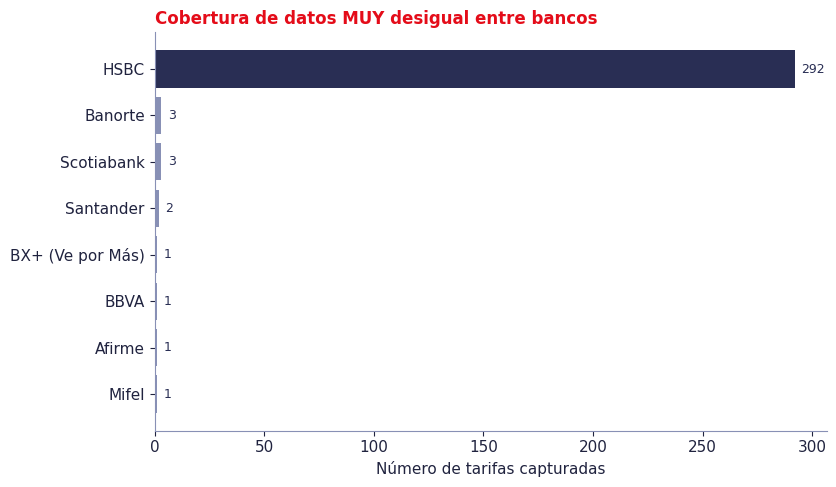

In [4]:
cobertura = df.groupby('banco').size().sort_values(ascending=False)
cobertura_pct = (cobertura / cobertura.sum() * 100).round(1)
tabla_cobertura = pd.DataFrame({'filas': cobertura, 'pct_del_total': cobertura_pct})
print(tabla_cobertura)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(cobertura.index[::-1], cobertura.values[::-1],
        color=[NAVY if v > 50 else '#8890B5' for v in cobertura.values[::-1]])
ax.set_xlabel('Número de tarifas capturadas')
ax.set_title('Cobertura de datos MUY desigual entre bancos', loc='left', fontsize=12, color=RED, fontweight='bold')
for i, v in enumerate(cobertura.values[::-1]):
    ax.text(v + 3, i, str(v), va='center', fontsize=9, color=NAVY)
plt.tight_layout(); plt.show()

## 3. Distribución de tasas por banco

Con la limitación de cobertura ya sobre la mesa, se muestra la distribución completa (no solo el promedio) para los bancos con más de una observación.

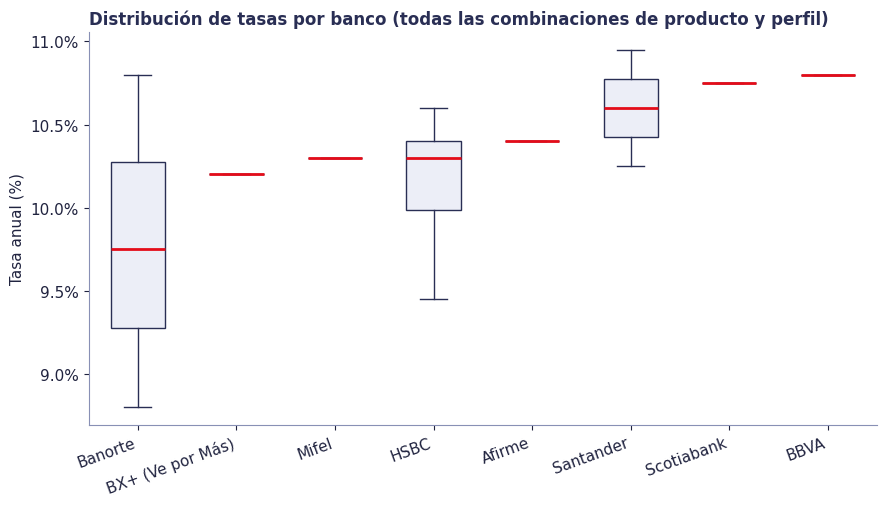

In [5]:
orden = df.groupby('banco')['tasa_pct'].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 5.2))
data = [df.loc[df.banco == b, 'tasa_pct'].values for b in orden]
ax.boxplot(data, tick_labels=orden, patch_artist=True, widths=0.55,
           medianprops={'color': RED, 'linewidth': 2}, boxprops={'facecolor': '#ECEEF7', 'edgecolor': NAVY},
           whiskerprops={'color': NAVY}, capprops={'color': NAVY},
           flierprops={'markerfacecolor': RED, 'markeredgecolor': RED, 'markersize': 4, 'alpha': 0.6})
ax.set_ylabel('Tasa anual (%)')
ax.set_title('Distribución de tasas por banco (todas las combinaciones de producto y perfil)', loc='left', fontsize=12, color=NAVY, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

**Lectura:** Banorte y HSBC muestran las tasas más bajas en mediana, Santander/Scotiabank/BBVA las más altas — pero recordando la sección 2, Banorte solo aporta 3 observaciones y BBVA solo 1, así que esa diferencia hay que tratarla como indicativa, no concluyente.

## 4. ¿Qué variables se relacionan con la tasa?

Se prueban dos relaciones que el negocio da por hecho: *"a mayor aforo, mayor tasa"* y *"a mayor plazo, mayor tasa"*. Se usa correlación de Spearman (no asume relación lineal ni distribución normal) además de Pearson.

Tasa vs aforo máximo   -> Pearson r=0.595 (p=0.0000) | Spearman rho=0.595 (p=0.0000)
Tasa vs plazo máximo   -> Pearson r=0.036 (p=0.5265)


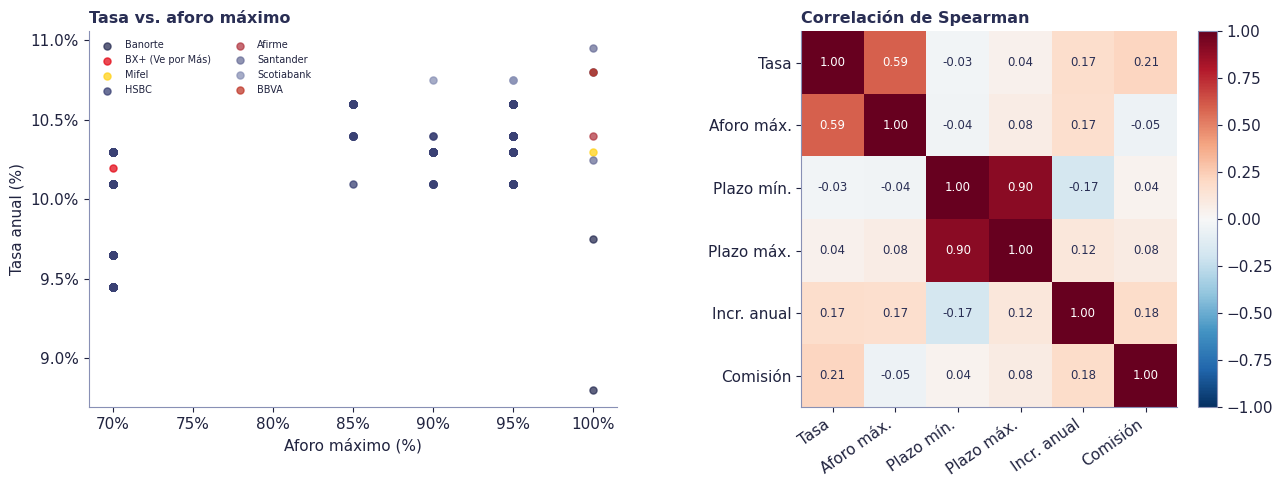

In [6]:
r_p, p_p = stats.pearsonr(df.aforo_max_pct, df.tasa_pct)
r_s, p_s = stats.spearmanr(df.aforo_max_pct, df.tasa_pct)
r_plazo, p_plazo = stats.pearsonr(df.plazo_max, df.tasa_pct)
print(f'Tasa vs aforo máximo   -> Pearson r={r_p:.3f} (p={p_p:.4f}) | Spearman rho={r_s:.3f} (p={p_s:.4f})')
print(f'Tasa vs plazo máximo   -> Pearson r={r_plazo:.3f} (p={p_plazo:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, b in enumerate(orden):
    sub = df[df.banco == b]
    axes[0].scatter(sub.aforo_max_pct, sub.tasa_pct, s=26, alpha=0.75, color=PAL[i % len(PAL)], label=b)
axes[0].set_xlabel('Aforo máximo (%)'); axes[0].set_ylabel('Tasa anual (%)')
axes[0].set_title('Tasa vs. aforo máximo', loc='left', fontsize=11.5, color=NAVY, fontweight='bold')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1)); axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].legend(fontsize=7, ncol=2, loc='upper left', frameon=False)

corr = df[['tasa_pct','aforo_max_pct','plazo_min','plazo_max','incremento_anual','comision_pct']].corr(method='spearman')
im = axes[1].imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
etiquetas = ['Tasa','Aforo máx.','Plazo mín.','Plazo máx.','Incr. anual','Comisión']
axes[1].set_xticks(range(6)); axes[1].set_xticklabels(etiquetas, rotation=35, ha='right')
axes[1].set_yticks(range(6)); axes[1].set_yticklabels(etiquetas)
for i in range(6):
    for j in range(6):
        v = corr.values[i,j]
        if not np.isnan(v): axes[1].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8.5, color='white' if abs(v)>0.5 else NAVY)
axes[1].set_title('Correlación de Spearman', loc='left', fontsize=11.5, color=NAVY, fontweight='bold')
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

**Resultado:** el supuesto de negocio *"mayor aforo → mayor tasa"* **sí tiene soporte estadístico** (r≈0.59, p<0.001): a mayor porcentaje de financiamiento del valor del inmueble, más cara la tasa — consistente con que un aforo alto implica más riesgo para el banco. En cambio, la relación *"mayor plazo → mayor tasa"* **no se sostiene** con estos datos (r≈0.04, p=0.53): el plazo del crédito no explica diferencias de tasa en esta muestra.

## 5. ¿Difieren las tasas entre bancos? (ANOVA / Kruskal-Wallis)

Se compara formalmente si las medias de tasa son iguales entre bancos. Antes de elegir la prueba, se valida el supuesto de normalidad (Shapiro-Wilk) por grupo.

In [7]:
print('Normalidad por banco (Shapiro-Wilk, solo grupos con n>=3):')
for b in orden:
    vals = df.loc[df.banco == b, 'tasa_pct'].values
    if len(vals) >= 3:
        w, p = stats.shapiro(vals)
        veredicto = 'NO normal' if p < 0.05 else 'no se rechaza normalidad'
        print(f'  {b:20s} n={len(vals):3d}  p={p:.4f}  ({veredicto})')

grupos = [df.loc[df.banco == b, 'tasa_pct'].values for b in orden]
f_stat, p_anova = stats.f_oneway(*grupos)
h_stat, p_kw = stats.kruskal(*grupos)
print(f'\nANOVA (paramétrica):        F={f_stat:.2f}, p={p_anova:.2e}')
print(f'Kruskal-Wallis (no paramétrica): H={h_stat:.2f}, p={p_kw:.2e}')

Normalidad por banco (Shapiro-Wilk, solo grupos con n>=3):
  Banorte              n=  3  p=0.9449  (no se rechaza normalidad)
  HSBC                 n=292  p=0.0000  (NO normal)
  Scotiabank           n=  3  p=1.0000  (no se rechaza normalidad)

ANOVA (paramétrica):        F=2.54, p=1.48e-02
Kruskal-Wallis (no paramétrica): H=14.64, p=4.09e-02


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


**Resultado:** ambas pruebas coinciden en rechazar la hipótesis de que todos los bancos cobran, en promedio, la misma tasa (p<0.05). Dado que HSBC (el grupo más grande) no pasa la prueba de normalidad, la lectura más honesta es la de Kruskal-Wallis, no la ANOVA paramétrica — y aun así el resultado se apoya desproporcionadamente en HSBC por su volumen, otra consecuencia directa de la cobertura desigual.

## 6. Análisis profundo dentro de HSBC (n=292 — la única muestra con potencia real)

Como los demás bancos no tienen volumen suficiente, esta sección explota la estructura interna de HSBC, que sí reporta su tabla completa de tasas por programa, perfil de riesgo y plazo.

In [8]:
h = df[df.banco == 'HSBC'].copy()
partes = h['perfil'].str.split(' · ', expand=True)
h['premier'] = partes[0].str.strip()
h['nomina'] = partes[1].str.strip()
h['riesgo'] = partes[2].str.strip()

# --- ¿El programa (tradicional / cofinavit / apoyo infonavit) afecta la tasa?
grupos_prog = [h.loc[h.programa == p, 'tasa_pct'].values for p in h.programa.unique()]
f_prog, p_prog = stats.f_oneway(*grupos_prog)
print('Tasa por programa dentro de HSBC:')
print(h.groupby('programa')['tasa_pct'].agg(['count','mean','std']).round(3))
print(f'ANOVA: F={f_prog:.2f}, p={p_prog:.3f}\n')

# --- ¿La banda de riesgo crediticio (NR) afecta la tasa?
riesgo_orden = sorted(h.riesgo.dropna().unique())
grupos_riesgo = [h.loc[h.riesgo == r, 'tasa_pct'].values for r in riesgo_orden]
f_riesgo, p_riesgo = stats.f_oneway(*grupos_riesgo)
print('Tasa por banda de riesgo crediticio (NR) dentro de HSBC:')
print(h.groupby('riesgo')['tasa_pct'].agg(['count','mean','std']).round(3).loc[riesgo_orden])
print(f'ANOVA: F={f_riesgo:.2f}, p={p_riesgo:.2e}')

Tasa por programa dentro de HSBC:
                 count    mean    std
programa                             
apoyo_infonavit     96  10.138  0.362
cofinavit           96  10.138  0.362
tradicional        100  10.152  0.362
ANOVA: F=0.05, p=0.952

Tasa por banda de riesgo crediticio (NR) dentro de HSBC:
            count    mean    std
riesgo                          
NR 1 y 2       73  10.237  0.098
NR 1 y 2 +     73   9.579  0.096
NR 3           73  10.525  0.108
NR 3 +         73  10.229  0.096
ANOVA: F=1174.65, p=3.83e-161


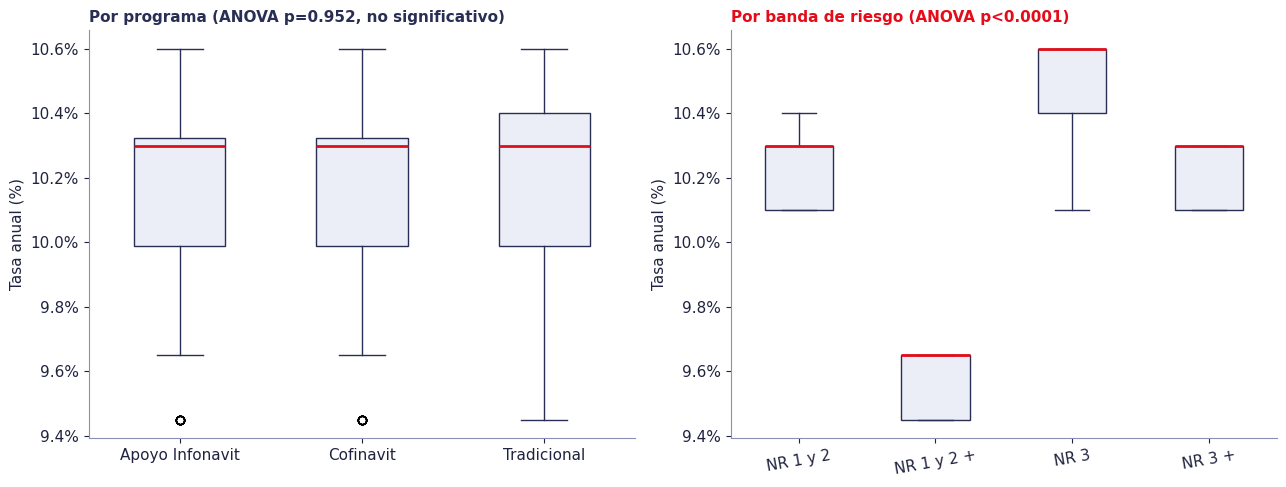

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
prog_orden = h.groupby('programa')['tasa_pct'].median().sort_values().index.tolist()
data = [h.loc[h.programa == pr, 'tasa_pct'].values for pr in prog_orden]
axes[0].boxplot(data, tick_labels=[p.replace('_',' ').title() for p in prog_orden], patch_artist=True, widths=0.5,
                medianprops={'color': RED,'linewidth':2}, boxprops={'facecolor':'#ECEEF7','edgecolor':NAVY},
                whiskerprops={'color':NAVY}, capprops={'color':NAVY})
axes[0].set_ylabel('Tasa anual (%)'); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
axes[0].set_title(f'Por programa (ANOVA p={p_prog:.3f}, no significativo)', loc='left', fontsize=11, color=NAVY, fontweight='bold')

data2 = [h.loc[h.riesgo == r, 'tasa_pct'].values for r in riesgo_orden]
axes[1].boxplot(data2, tick_labels=riesgo_orden, patch_artist=True, widths=0.5,
                medianprops={'color': RED,'linewidth':2}, boxprops={'facecolor':'#ECEEF7','edgecolor':NAVY},
                whiskerprops={'color':NAVY}, capprops={'color':NAVY})
axes[1].set_ylabel('Tasa anual (%)'); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
axes[1].set_title(f'Por banda de riesgo (ANOVA p<0.0001)', loc='left', fontsize=11, color=RED, fontweight='bold')
plt.xticks(rotation=10)
plt.tight_layout(); plt.show()

**Hallazgo principal de esta sección:** el **programa** (tradicional / Cofinavit / Apoyo Infonavit) **no** cambia la tasa dentro de HSBC (p=0.95 — las tres medias son prácticamente idénticas, 10.14–10.15%). Lo que sí determina la tasa, con altísima significancia (p<0.0001) y una diferencia de más de 0.9 puntos porcentuales entre el mejor y el peor segmento, es la **banda de riesgo crediticio (NR)** — y de forma no trivial: el sufijo "+" (que denota una condición adicional favorable, como domiciliar nómina) reduce la tasa dentro de cada banda NR, pero cruzar de NR-1-y-2 a NR-3 la sube. Esto es información accionable para ESJOAN: **negociar el programa correcto importa menos que ayudar al cliente a calificar en la mejor banda de riesgo posible.**

## 7. Comisión por apertura: ¿quién cobra y cuánto?

In [10]:
con_comision = df[df.tiene_comision]
resumen_comision = con_comision.groupby('banco')['comision_pct'].agg(['count','mean','min','max']).round(2)
print(resumen_comision)
sin_comision = sorted(set(df.banco.unique()) - set(resumen_comision.index))
print('\nBancos sin comisión de apertura registrada en sus tarifas:', sin_comision)

            count  mean   min   max
banco                              
HSBC          292  0.48  0.00  1.00
Scotiabank      3  0.92  0.75  1.25

Bancos sin comisión de apertura registrada en sus tarifas: ['Afirme', 'BBVA', 'BX+ (Ve por Más)', 'Banorte', 'Mifel', 'Santander']


Solo HSBC y Scotiabank tienen comisión por apertura capturada en sus tarifas (0.0–1.0% y 0.75–1.25% respectivamente); en el resto de los bancos, o no se cobra, o su Excel original no la desglosaba por fila y quedó como parámetro fijo del banco (fuera de esta tabla). Vale la pena confirmarlo con cada banco antes de usarlo como comparación definitiva.

## 8. Conclusiones y limitaciones (honestas)

**Conclusiones con soporte estadístico:**
1. El aforo máximo se correlaciona con la tasa (Spearman ρ=0.59, p<0.001) — a mayor financiamiento relativo, mayor tasa.
2. El plazo del crédito **no** predice la tasa (p=0.53) en estos datos.
3. Dentro de HSBC, la banda de riesgo crediticio es, por mucho, el factor más determinante de la tasa (p<0.0001); el programa de crédito (tradicional/Cofinavit/Infonavit) no lo es (p=0.95).
4. Solo 2 de 8 bancos activos reportan comisión por apertura en el detalle de sus tarifas.

**Limitación central, y la más importante de todo el análisis:** la cobertura de datos es extremadamente desigual — HSBC concentra 96% de las filas (292 de 304); los otros 7 bancos activos aportan entre 1 y 3 filas cada uno. Esto significa que:
- Las comparaciones *entre* bancos (secciones 3 y 5) son **indicativas, no concluyentes** — con n=1 no hay manera de saber si esa tasa es representativa o un caso puntual negociado.
- Las conclusiones robustas de este notebook (sección 6) son válidas **específicamente para HSBC**, no generalizables al resto del mercado sin más datos.
- **Siguiente paso recomendado para el negocio:** capturar la tabla completa de tarifas (no solo la tasa de referencia) de al menos 2-3 bancos adicionales, para poder repetir el análisis de la sección 6 de forma comparativa entre instituciones.
